# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** _____Dominik Caleb Moreno Hernández_____________________________  
**Grupo:** ________511__________  **Fecha:** ___________26/10/2026_______

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")

print("Primeras cinco filas:")
display(df.head())

print("\nDimensiones (filas, columnas):", df.shape)

print("\nNombres de las columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))

print("\nResumen estadístico de las columnas numéricas:")
display(df.describe().round(2))

print("\nValores existentes en payment_type (incluye nulos):")
display(df["payment_type"].value_counts(dropna=False).to_frame("viajes"))

Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000



Dimensiones (filas, columnas): (2427612, 20)

Nombres de las columnas:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:


,tipo
VendorID,int64
tpep_pickup_datetime,str
tpep_dropoff_datetime,str
passenger_count,float64
trip_distance,float64
RatecodeID,float64
PULocationID,float64
DOLocationID,float64
payment_type,float64
fare_amount,float64



Resumen estadístico de las columnas numéricas:


,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2427612.00,2415489.00,2415470.00,2415474.00,2415487.00,2415475.00,2415487.00,2415488.00,2415487.00,2415462.00,2415459.00,2415465.00,2415481.00,2415484.00,2415457.00,2415481.00,2415462.00,2415475.00
mean,1.89,1.30,3.30,4.23,164.14,163.22,1.17,38.53,1.57,0.48,3.67,0.59,0.99,29.38,2.25,0.20,0.56,15.61
std,0.81,1.88,5.17,17.20,62.85,69.26,0.46,542.38,1.91,0.10,4.23,2.39,0.16,25.93,0.78,0.63,0.33,260.58
min,1.00,-5.00,-99.99,1.00,1.00,1.00,1.00,-1849.60,-7.50,-0.50,-90.00,-106.46,-1.00,-1866.89,-2.50,-2.00,-0.75,-300517.52
25%,2.00,1.00,0.99,1.00,132.00,113.00,1.00,9.30,0.00,0.50,1.00,0.00,1.00,16.38,2.50,0.00,0.75,7.28
50%,2.00,1.00,1.70,1.00,161.00,162.00,1.00,13.50,1.00,0.50,2.95,0.00,1.00,21.54,2.50,0.00,0.75,12.32
75%,2.00,1.00,3.36,1.00,232.00,234.00,1.00,21.90,2.50,0.50,4.56,0.00,1.00,31.45,2.50,0.00,0.75,20.12
max,7.00,100.00,1686.49,99.00,265.00,265.00,4.00,19995.59,23.25,11.50,444.44,616.79,1.00,5530.74,2.75,27.00,0.75,8373.67



Valores existentes en payment_type (incluye nulos):


,viajes
payment_type,
1.0,2051983
2.0,329533
4.0,23558
NaN,12125
3.0,10413


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
df_limpio = df.copy()

print("Antes de limpiar:", df_limpio.shape)
print("\nValores nulos por columna:")
display(df_limpio.isna().sum().to_frame("nulos"))
print("Registros duplicados:", df_limpio.duplicated().sum())

df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()
print("\nDespués de eliminar duplicados y nulos:", df_limpio.shape)

df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
].copy()

print("Después de aplicar las condiciones:", df_limpio.shape)
print("Registros que quedan después de limpiar:", len(df_limpio))

Antes de limpiar: (2427612, 20)

Valores nulos por columna:


,nulos
VendorID,0
tpep_pickup_datetime,12126
tpep_dropoff_datetime,12127
passenger_count,12123
trip_distance,12142
RatecodeID,12138
PULocationID,12125
DOLocationID,12137
payment_type,12125
fare_amount,12124


Registros duplicados: 11961



Después de eliminar duplicados y nulos: (2196158, 20)


Después de aplicar las condiciones: (2096600, 20)
Registros que quedan después de limpiar: 2096600


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [3]:
tipos_pago = {1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute"}
df_limpio["payment_type_desc"] = df_limpio["payment_type"].map(tipos_pago)

df_cash = df_limpio[df_limpio["payment_type_desc"] == "Cash"].copy()
X = df_cash[["passenger_count", "trip_distance"]].copy()

print("Viajes pagados en efectivo (Cash):", len(df_cash))
display(X.describe().round(2))

Viajes pagados en efectivo (Cash): 282085


,passenger_count,trip_distance
count,282085.00,282085.00
mean,1.34,3.84
std,0.76,6.21
min,1.00,0.01
25%,1.00,0.92
50%,1.00,1.70
75%,1.00,4.37
max,6.00,1686.49


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [4]:
X_log = np.log1p(X)

escalador = StandardScaler()
X_escalado = pd.DataFrame(
    escalador.fit_transform(X_log),
    columns=X.columns,
    index=X.index
)

print("Variables después de log1p:")
display(X_log.describe().round(3))

print("Variables estandarizadas (media ≈ 0 y desviación estándar ≈ 1):")
display(X_escalado.describe().round(3))

Variables después de log1p:


,passenger_count,trip_distance
count,282085.000,282085.000
mean,0.815,1.225
std,0.250,0.763
min,0.693,0.010
25%,0.693,0.652
50%,0.693,0.993
75%,0.693,1.681
max,1.946,7.431


Variables estandarizadas (media ≈ 0 y desviación estándar ≈ 1):


,passenger_count,trip_distance
count,282085.000,282085.000
mean,-0.000,0.000
std,1.000,1.000
min,-0.486,-1.592
25%,-0.486,-0.751
50%,-0.486,-0.304
75%,-0.486,0.597
max,4.520,8.130


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,324581.940,0.550
1,3,160363.188,0.612
2,4,115075.583,0.620
3,5,86895.898,0.625
4,6,61144.889,0.562


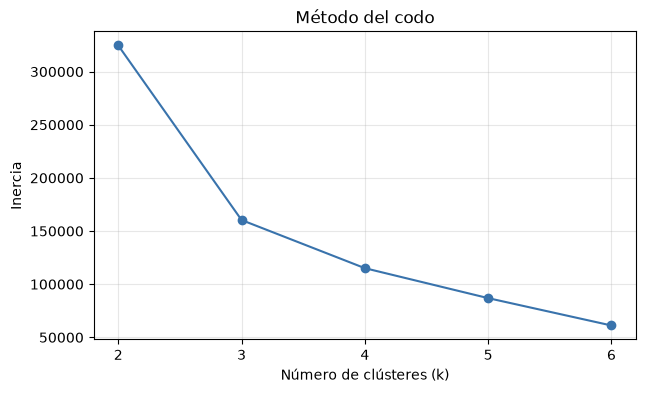

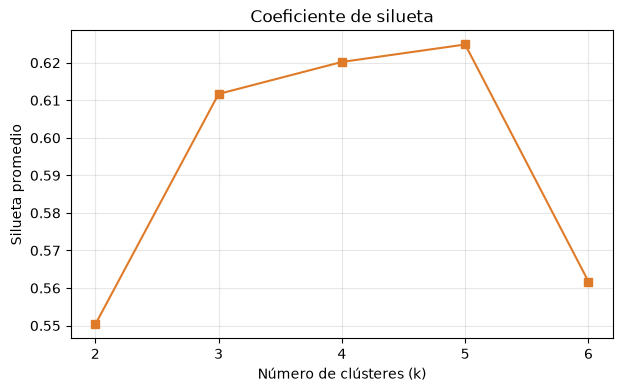

In [5]:
resultados = []

for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo.fit_predict(X_escalado)
    silueta = silhouette_score(X_escalado, etiquetas_k, sample_size=5000, random_state=42)
    resultados.append({"k": k, "Inercia": modelo.inertia_, "Silueta": silueta})

metricas = pd.DataFrame(resultados)
display(metricas.round(3))

plt.figure(figsize=(7, 4))
plt.plot(metricas["k"], metricas["Inercia"], marker="o", color="#3973ac")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(metricas["k"])
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(metricas["k"], metricas["Silueta"], marker="s", color="#df7b28")
plt.title("Coeficiente de silueta")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silueta promedio")
plt.xticks(metricas["k"])
plt.grid(alpha=0.3)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

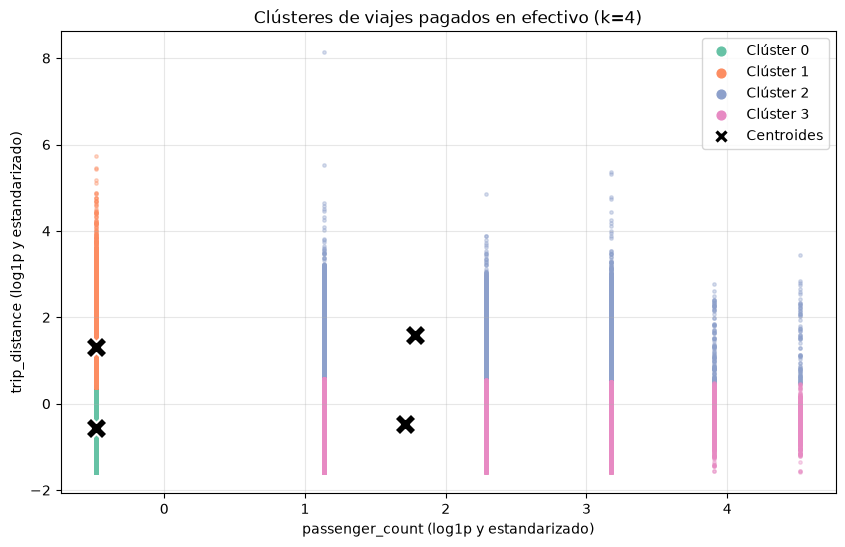

In [6]:
k_final = 4

modelo_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas = modelo_final.fit_predict(X_escalado)

plt.figure(figsize=(10, 6))
colores = plt.cm.Set2(np.arange(k_final))

for grupo in range(k_final):
    puntos = X_escalado[etiquetas == grupo]
    plt.scatter(
        puntos["passenger_count"], puntos["trip_distance"],
        s=6, alpha=0.35, color=colores[grupo], label=f"Clúster {grupo}"
    )

centroides = modelo_final.cluster_centers_
plt.scatter(
    centroides[:, 0], centroides[:, 1],
    marker="X", s=250, color="black", edgecolor="white", linewidth=1.5,
    zorder=5, label="Centroides"
)

plt.title(f"Clústeres de viajes pagados en efectivo (k={k_final})")
plt.xlabel("passenger_count (log1p y estandarizado)")
plt.ylabel("trip_distance (log1p y estandarizado)")

leyenda = plt.legend()
for marcador in leyenda.legend_handles[:k_final]:
    marcador.set_sizes([40])
    marcador.set_alpha(1)
leyenda.legend_handles[k_final].set_sizes([120])

plt.grid(alpha=0.3)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [7]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

tabla_clusters = (
    df_resultado
    .groupby("cluster")
    .agg(
        viajes=("passenger_count", "size"),
        pasajeros_media=("passenger_count", "mean"),
        pasajeros_mediana=("passenger_count", "median"),
        distancia_media_millas=("trip_distance", "mean"),
        distancia_mediana_millas=("trip_distance", "median"),
    )
    .round(2)
)

display(tabla_clusters)

,viajes,pasajeros_media,pasajeros_mediana,distancia_media_millas,distancia_mediana_millas
cluster,,,,,
0,160372,1.00,1.0,1.36,1.20
1,59946,1.00,1.0,9.55,7.96
2,18849,2.62,2.0,12.08,10.37
3,42918,2.55,2.0,1.53,1.30


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** Elegí k = 4. La inercia baja mucho al pasar de 2 a 3 grupos (de 324,581.9 a 160,363.2) y después baja cada vez menos: 115,075.6 con 4 grupos, 86,895.9 con 5 y 61,144.9 con 6. Por eso el codo queda entre 3 y 4. La silueta sube de 0.550 con 2 grupos a 0.612 con 3 y a 0.620 con 4, llega a 0.625 con 5 y baja a 0.562 con 6. Entre 4 y 5 grupos la diferencia es de solo 0.005, así que no vale la pena agregar un grupo más. También me quedé con 4 porque los grupos se pueden explicar mejor: con 3 grupos los viajes de varios pasajeros quedaban todos juntos, aunque unos eran cortos y otros largos.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:** El clúster 0 es el más grande, con 160,372 viajes. Son viajes de un pasajero (media y mediana de 1.00) y de distancia corta, con una media de 1.36 millas y una mediana de 1.20, por eso lo llamé viajes cortos de un pasajero. El clúster 1 tiene 59,946 viajes, también de un pasajero, pero más largos: la media es de 9.55 millas y la mediana de 7.96, así que lo llamé viajes largos de un pasajero. El clúster 2 es el más pequeño, con 18,849 viajes, tiene una media de 2.62 pasajeros (mediana de 2) y las distancias más largas, con 12.08 millas de media y 10.37 de mediana, por lo que lo llamé viajes largos con varios pasajeros. El clúster 3 tiene 42,918 viajes con 2.55 pasajeros de media (mediana de 2), pero cortos, con 1.53 millas de media y 1.30 de mediana, así que lo llamé viajes cortos con varios pasajeros. En todos los grupos la media de la distancia es más alta que la mediana, lo que quiere decir que hay  algunos viajes muy largos que suben el promedio.

**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta:** Los grupos con menos pasajeros son el 0 y el 1, los dos con una media de 1.00, y juntos suman 220,318 viajes, cerca del 78% del total. Los grupos con más pasajeros son el 2 y el 3, con medias de 2.62 y 2.55, y suman 61,767 viajes, alrededor del 22%. Es decir, la mayoría de los viajes en efectivo es de una sola persona. En la distancia no hay una diferencia tan clara entre los dos tipos, porque cada uno tiene un grupo corto y uno largo: con un pasajero las medias son 1.36 y 9.55 millas, y con varios pasajeros son 1.53 y 12.08.

**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta:** No. El grupo con la distancia más larga (clúster 2, con una mediana de 10.37 millas) sí tiene varios pasajeros, pero el clúster 3 también tiene varios pasajeros y su mediana es de solo 1.30 millas. Además, los viajes largos de un pasajero (clúster 1) tienen una mediana de 7.96 millas, mucho más que la del clúster 3. Por eso, con estos grupos se ve que hay viajes cortos con varios pasajeros y viajes largos con una sola persona, y que no todos los viajes se comportan igual.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**